In [4]:
#1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

sns.set_theme(style="whitegrid")
events = pd.read_excel("NHL-playoffs-2026.xlsx", index_col=0)

print(events.shape)
events.iloc[:10, [2, 3, 4, 9, 12]]

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Считываем Excel-файл с помощью pd.read_excel() и сохраняем данные в таблицу events. Первый столбец используем как индекс. Затем проверяем размер таблицы и выводим первые 10 строк по выбранным столбцам.

Таблица содержит 29 710 строк и 38 столбцов.

In [5]:
#2
games = events.groupby("Game ID").agg({
    "Date": "first",
    "Away Team": "first",
    "Home Team": "first",
    "Cumulated Away Score": "max",
    "Cumulated Home Score": "max",
    "Period": "max"
})

games = games.rename(columns={
    "Cumulated Away Score": "Away Score",
    "Cumulated Home Score": "Home Score"
})
def make_outcome(period):
    if period <= 3:
        return "Final"
    elif period == 4:
        return "Final/OT"
    else:
        return "Final/" + str(period - 3) + "OT"
games["Outcome"] = games["Period"].apply(make_outcome)
games = games.drop(columns="Period")
games.tail()

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final
2025030415,2026-06-11,Vegas Golden Knights,Carolina Hurricanes,2,4,Final
2025030416,2026-06-14,Carolina Hurricanes,Vegas Golden Knights,3,0,Final


Группируем исходные данные по Game ID, чтобы каждой игре соответствовала одна строка. Для даты и названий команд берем первое значение, а для накопленного счета и номера периода максимальное. После этого переименовываем столбцы со счетом и с помощью функции outcome() определяем результат матча.
В результате получаем таблицу games с основной информацией по каждому матчу: датой, командами, итоговым счетом и результатом.

In [6]:
#3
def gameInfo(gameId):
    row = games.loc[gameId]
    text = (
        str(row["Home Team"]) + " - " +
        str(row["Away Team"]) +
        " (" +
        str(row["Home Score"]) + " - " +
        str(row["Away Score"]) +
        ", " +
        str(row["Outcome"]) +
        ", " +
        str(row["Date"]) +
        ")"
    )
    return text
print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


Создаем функцию gameInfo(), которая по номеру игры находит нужную строку в таблице games и объединяет название команд, счет, результат и дату в одну строку. Функция позволяет удобно получать краткую информацию о любом матче по его Game ID

In [7]:
#4
games["Total Score"] = (
    games["Away Score"] + games["Home Score"]
)
games["Total Score"].describe()

,Total Score
count,82.000000
mean,5.926829
std,2.259578
min,1.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,15.000000


Создаем столбец Total Score, складывая количество голов хозяев и гостей. С помощью describe() выводим основные описательные статистики этого показателя.
Среднее число голов за матч составляет около 5,93, медиана равна 6. Минимальное значение 1 гол, максимальное 15 голов.

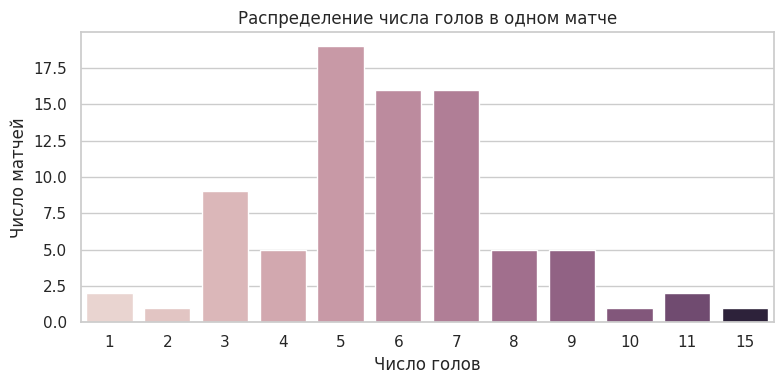

In [8]:
#5
plt.figure(figsize=(8, 4))

sns.countplot(
    data=games,
    x="Total Score",
    hue="Total Score",
    legend=False
)
plt.xlabel("Число голов")
plt.ylabel("Число матчей")
plt.title("Распределение числа голов в одном матче")

plt.tight_layout()
plt.show()

Строим countplot для показателя Total Score. По горизонтальной оси показываем число голов в матче, а по вертикальной количество матчей с таким числом голов.
Чаще всего встречаются матчи с примерно 5-7 голами. Матчи с очень маленьким или очень большим количеством голов встречаются реже.

In [9]:
#6
min_score = games["Total Score"].min()
max_score = games["Total Score"].max()
min_games_ids = games.index[
    games["Total Score"] == min_score
]

max_games_ids = games.index[
    games["Total Score"] == max_score
]
min_games = [
    gameInfo(game_id)
    for game_id in min_games_ids
]

max_games = [
    gameInfo(game_id)
    for game_id in max_games_ids
]
print("Самые нерезультативные игры:")
print(min_games)

print("\nСамые результативные игры:")
print(max_games)

Самые нерезультативные игры:
['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)', 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

Самые результативные игры:
['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']


С помощью .min() и .max() находим минимальное и максимальное значение Total Score. Затем выбираем матчи с этими значениями и выводим их с помощью функции gameInfo().
Самые нерезультативные матчи: Montréal Canadiens - Tampa Bay Lightning (0 - 1) и Philadelphia Flyers - Pittsburgh Penguins (1 - 0). Самый результативный матч: Colorado Avalanche - Minnesota Wild (9 - 6).

In [10]:
#7
away_player_cols = [
    "Away Team's Player on the Ice #1",
    "Away Team's Player on the Ice #2",
    "Away Team's Player on the Ice #3",
    "Away Team's Player on the Ice #4",
    "Away Team's Player on the Ice #5",
    "Away Team's Player on the Ice #6",
    "Away Team's Goalie"
]
home_player_cols = [
    "Home Team's Player on the Ice #1",
    "Home Team's Player on the Ice #2",
    "Home Team's Player on the Ice #3",
    "Home Team's Player on the Ice #4",
    "Home Team's Player on the Ice #5",
    "Home Team's Player on the Ice #6",
    "Home Team's Goalie"
]
player_cols = away_player_cols + home_player_cols
player_count_dict = {}

for game_id, one_game in events.groupby("Game ID"):
    all_names = one_game[player_cols].values.ravel()
    all_names = pd.Series(all_names).dropna().unique()
    player_count_dict[game_id] = len(all_names)
player_count = pd.Series(
    player_count_dict,
    name="Player Count"
)
max_players = player_count.max()

max_player_games = player_count[
    player_count == max_players
]
answer7 = pd.DataFrame(
    index=max_player_games.index
)

answer7["Game Info"] = [
    gameInfo(game_id)
    for game_id in answer7.index
]

answer7["Player Count"] = max_player_games
answer7


,Game Info,Player Count
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Для каждого матча объединяем столбцы с игроками и вратарями обеих команд. С помощью dropna() убираем пустые значения, а unique() оставляет каждую фамилию только один раз. Затем считаем число уникальных игроков.
Максимальное количество уникальных игроков в одном матче равно 40. Значение 41 из примера задания получается, если учитывать пустое значение NaN как отдельное значение.

In [15]:
#8
shot_types = [
    "shot-on-goal",
    "goal",
    "missed-shot"
]

shots = events[
    events["Play Type"].isin(shot_types)
].copy()
def get_goal_x(row):

    home_side = row["Home Team's Defending Side"]

    shooting_team = row["Team Making the Play"]

    home_team = row["Home Team"]

    if home_side == "left":

        if shooting_team == home_team:
            return 89
        else:
            return -89

    else:

        if shooting_team == home_team:
            return -89
        else:
            return 89
def get_shot_length(row):

    x = row["X Coordinate on the Ice Rink"]
    y = row["Y Coordinate on the Ice Rink"]

    goal_x = get_goal_x(row)

    if y < -3:

        distance = math.sqrt(
            (x - goal_x)**2 +
            (y + 3)**2
        )

    elif y <= 3:

        distance = abs(x - goal_x)

    else:

        distance = math.sqrt(
            (x - goal_x)**2 +
            (y - 3)**2
        )

    return distance
shots["Shot Length"] = shots.apply(
    get_shot_length,
    axis=1
)
print(len(shots))

shots[
    [
        "Game ID",
        "Play Type",
        "Shot Length"
    ]
]

7266


,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.206556
9,2025030111,missed-shot,12.000000
12,2025030111,missed-shot,29.410882
13,2025030111,shot-on-goal,62.169124
19,2025030111,missed-shot,52.924474
...,...,...,...
29695,2025030416,missed-shot,54.083269
29696,2025030416,missed-shot,5.099020
29704,2025030416,goal,46.238512
29706,2025030416,missed-shot,60.926185


Оставляем только события shot-on-goal, goal и missed-shot. Для каждого броска определяем координату ворот в зависимости от стороны защиты и команды, выполняющей бросок. Затем рассчитываем расстояние до ближайшей точки ворот по формуле из задания и записываем его в Shot Length.
Для каждого подходящего броска рассчитано расстояние до ворот. Всего рассматривается 7 266 бросков.

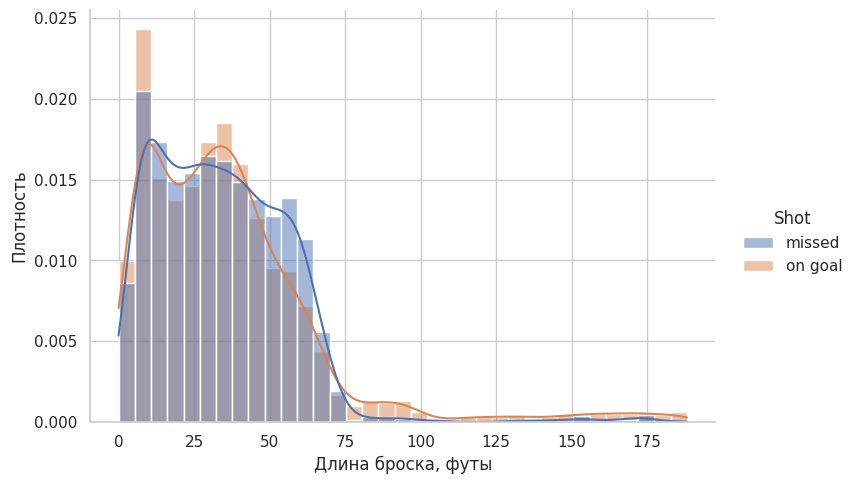

,count,mean,median,max
Shot,,,,
missed,2643,34.014,32.249,185.068
on goal,4623,36.207,31.828,188.215


In [14]:
#9
shots["Shot"] = shots["Play Type"].replace({
    "missed-shot": "missed",
    "shot-on-goal": "on goal",
    "goal": "on goal"
})
g = sns.displot(
    data=shots,
    x="Shot Length",
    hue="Shot",
    stat="density",
    common_norm=False,
    bins=35,
    kde=True,
    height=5,
    aspect=1.5
)

g.set_axis_labels(
    "Длина броска, футы",
    "Плотность"
)

plt.show()
shots.groupby("Shot")["Shot Length"].agg(
    ["count", "mean", "median", "max"]
).round(3)

Делим броски на две группы: точные (goal и shot-on-goal) и неточные (missed-shot). Затем строим распределения расстояний с помощью sns.displot(). Используем плотность, чтобы можно было сравнивать группы разного размера.
Распределения точных и неточных бросков в целом похожи. У точных бросков присутствуют очень большие расстояния, что может быть связано с бросками по пустым воротам.

In [13]:
#10
unblocked = events[
    events["Play Type"].isin([
        "shot-on-goal",
        "goal",
        "missed-shot"
    ])
].copy()
unblocked["On Goal"] = (
    unblocked["Play Type"]
    .isin([
        "shot-on-goal",
        "goal"
    ])
    .astype(int)
)
numshots = unblocked.groupby(
    [
        "Game ID",
        "Team Making the Play"
    ]
).agg(
    Shots_on_Goal=("On Goal", "sum"),
    All_Unblocked_Shots=("On Goal", "count")
)
numshots["Share of Shots on Goal"] = (
    numshots["Shots_on_Goal"] /
    numshots["All_Unblocked_Shots"]
)
numshots["Share of Shots on Goal"]

Game ID     Team Making the Play
2025030111  Boston Bruins           0.625000
            Buffalo Sabres          0.678571
2025030112  Boston Bruins           0.613636
            Buffalo Sabres          0.636364
2025030113  Boston Bruins           0.694444
                                      ...   
2025030414  Vegas Golden Knights    0.583333
2025030415  Carolina Hurricanes     0.558140
            Vegas Golden Knights    0.510204
2025030416  Carolina Hurricanes     0.638889
            Vegas Golden Knights    0.594595
Name: Share of Shots on Goal, Length: 164, dtype: float64

Оставляем все незаблокированные броски. Создаем показатель On Goal, который показывает, попал бросок в створ или нет. Затем группируем данные по матчу и команде, считаем число точных и общее число бросков и находим их отношение.
Получена доля бросков в створ для каждой команды в каждом отдельном матче.

In [19]:
#11
avgnumshots = numshots.groupby(
    "Team Making the Play"
)["Share of Shots on Goal"].mean()

print("5 самых высоких значений:")
print(avgnumshots.nlargest(5).round(3))
print()
print("5 самых низких значений:")
print(avgnumshots.nsmallest(5).round(3))


5 самых высоких значений:
Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

5 самых низких значений:
Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64


Для каждой команды усредняем долю точных бросков по всем ее матчам. Затем с помощью nlargest(5) выводим пять самых высоких значений, а с помощью nsmallest(5) пять самых низких.
Самая высокая средняя доля точных бросков у Edmonton Oilers 0,706. Самая низкая у Pittsburgh Penguins, 0,554.

In [22]:
#12
unblocked["Shot"] = unblocked["Play Type"].isin(
    ["shot-on-goal", "goal"]
).astype(int)

unblocked["Goal"] = (
    unblocked["Play Type"] == "goal"
).astype(int)

team_games = unblocked.groupby(
    ["Game ID", "Team Making the Play"]
)[["Shot", "Goal"]].sum()

avgshots = team_games.groupby(
    "Team Making the Play"
)[["Shot", "Goal"]].mean()

avgshots.round(3)


,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Создаем два показателя, Shot для бросков в створ и Goal для голов. Сначала считаем их количество для каждой команды в каждом матче, а затем рассчитываем средние значения по всем матчам команды.
Получаем таблица со средним количеством бросков в створ и голов за матч для каждой из 16 команд.

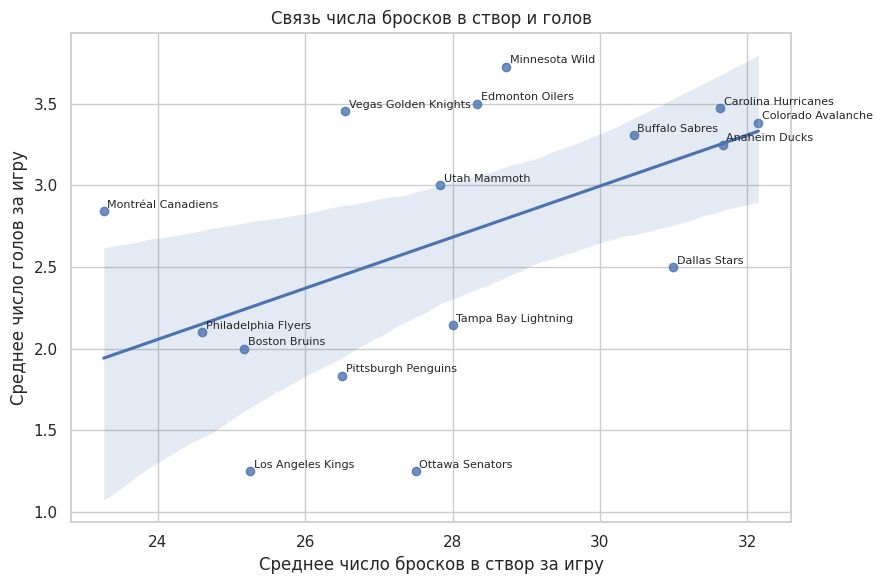

Корреляция: 0.521


In [25]:
#13
plt.figure(figsize=(9, 6))

sns.regplot(
    data=avgshots,
    x="Shot",
    y="Goal"
)
for team, row in avgshots.iterrows():

    plt.text(
        row["Shot"] + 0.05,
        row["Goal"] + 0.02,
        team,
        fontsize=8
    )
plt.xlabel(
    "Среднее число бросков в створ за игру"
)
plt.ylabel(
    "Среднее число голов за игру"
)
plt.title(
    "Связь числа бросков в створ и голов"
)
plt.tight_layout()
plt.show()
correlation = avgshots["Shot"].corr(
    avgshots["Goal"]
)

print(
    "Корреляция:",
    round(correlation, 3)
)

С помощью sns.regplot() строим график зависимости среднего количества голов от среднего количества бросков в створ. Дополнительно с помощью .corr() рассчитываем коэффициент корреляции.
Корреляция составляет около 0,52. Связь положительная: команды с большим количеством бросков в створ в среднем забивают больше, однако зависимость не очень сильная.

In [26]:
#14
all_attempt_types = [
    "shot-on-goal",
    "goal",
    "missed-shot",
    "blocked-shot"
]
all_attempts = events[
    events["Play Type"].isin(
        all_attempt_types
    )
].copy()
attempts_per_game = all_attempts.groupby(
    "Game ID"
).size()
idxmax = attempts_per_game.idxmax()
print(
    "Максимум бросков:",
    attempts_per_game.max()
)

print(
    gameInfo(idxmax)
)

Максимум бросков: 208
Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)


Оставляем все попытки броска: голы, броски в створ, промахи и заблокированные броски. С помощью groupby() и size() считаем их число в каждом матче. idxmax() позволяет найти номер игры с максимальным количеством попыток.
Максимальное количество попыток броска равно 208. Это матч Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20).

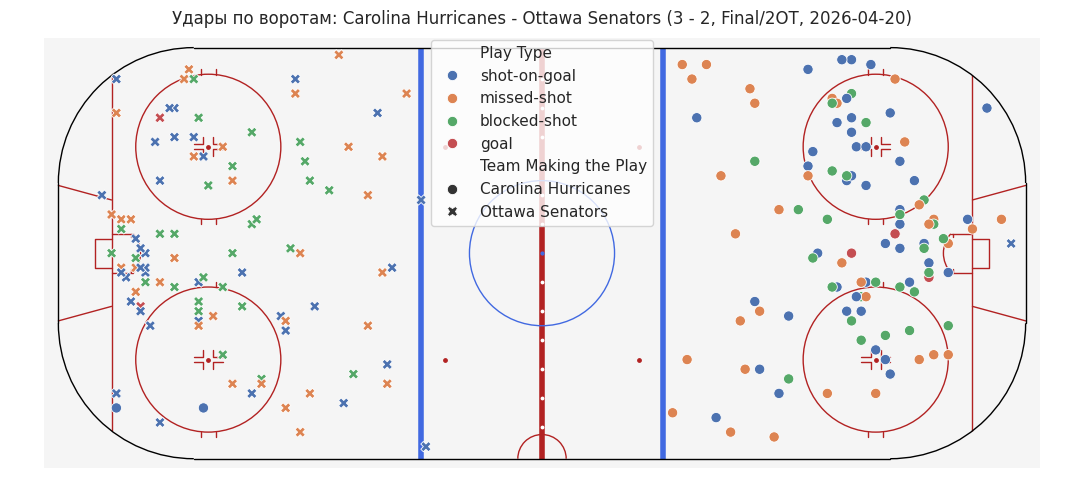

In [28]:
#15
from rink import plot_rink
game_attempts = all_attempts[
    all_attempts["Game ID"] == idxmax
].copy()
game_attempts["X Plot"] = (
    game_attempts[
        "X Coordinate on the Ice Rink"
    ]
)

game_attempts["Y Plot"] = (
    game_attempts[
        "Y Coordinate on the Ice Rink"
    ]
)
odd_period = (
    game_attempts["Period"] % 2 == 1
)
game_attempts.loc[
    odd_period,
    "X Plot"
] = (
    -game_attempts.loc[
        odd_period,
        "X Plot"
    ]
)
game_attempts.loc[
    odd_period,
    "Y Plot"
] = (
    -game_attempts.loc[
        odd_period,
        "Y Plot"
    ]
)
plt.figure(figsize=(11, 5))

plot_rink(False)

sns.scatterplot(
    data=game_attempts,
    x="X Plot",
    y="Y Plot",
    hue="Play Type",
    style="Team Making the Play",
    s=55
)

plt.axis("equal")
plt.axis("off")

plt.title(
    "Удары по воротам: " +
    gameInfo(idxmax)
)

plt.tight_layout()

plt.show()

Выбираем броски из матча, найденного в предыдущем задании. В нечетных периодах меняем знаки координат X и Y согласно условию. Затем рисуем хоккейную площадку с помощью plot_rink() и наносим на нее броски через scatterplot().
Получена карта всех попыток броска в выбранном матче. Цвет показывает исход броска, а форма точки команду.

In [29]:
#16
goal_events = events[
    events["Play Type"] == "goal"
].copy()
goal_counts = goal_events[
    "Player in the Event #1"
].value_counts()
top_scorers = goal_counts.head(10)

top_scorers

,count
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Jordan Staal,8
Nikolaj Ehlers,8
Nathan MacKinnon,7
Taylor Hall,7
Mark Stone,7


Оставляем только события goal. В столбце Player in the Event #1 находится игрок, забивший гол. С помощью value_counts() считаем количество голов и выводим первые 10 игроков.
Больше всего голов забил Brett Howden (14)

In [30]:
#17
assist_players = pd.concat([
    goal_events[
        "Player in the Event #2"
    ],

    goal_events[
        "Player in the Event #3"
    ]
]).dropna()
assist_counts = (
    assist_players.value_counts()
)
top_assists = assist_counts.head(10)
top_assists

,count
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Taylor Hall,12
Martin Necas,12
Nick Suzuki,12
Shea Theodore,12
Quinn Hughes,11
Kirill Kaprizov,11


Объединяем столбцы Player in the Event #2 и Player in the Event #3, в которых записаны игроки, сделавшие голевые передачи. Удаляем пустые значения и считаем количество передач каждого игрока.
Больше всего голевых передач сделал Jack Eichel (20).

In [31]:
#18
points = goal_counts.add(
    assist_counts,
    fill_value=0
)
points = (
    points
    .sort_values(
        ascending=False
    )
    .astype(int)
)
top_points = points.head(10)

top_points

,count
Mitch Marner,29
Jack Eichel,22
Jackson Blake,20
Taylor Hall,19
Shea Theodore,18
Nikolaj Ehlers,18
Brett Howden,18
Nick Suzuki,16
Lane Hutson,16
Pavel Dorofeyev,16


Отдельно считаем количество голов и передач каждого игрока. Затем складываем эти показатели с помощью .add(). fill_value=0 позволяет корректно учитывать игроков, у которых есть только голы или только передачи.
Больше всего очков по системе «гол + пас» набрал Mitch Marner (29).

In [41]:
#19
# Задание 19

player_columns = [
    "Away Team's Player on the Ice #1",
    "Away Team's Player on the Ice #2",
    "Away Team's Player on the Ice #3",
    "Away Team's Player on the Ice #4",
    "Away Team's Player on the Ice #5",
    "Away Team's Player on the Ice #6",
    "Home Team's Player on the Ice #1",
    "Home Team's Player on the Ice #2",
    "Home Team's Player on the Ice #3",
    "Home Team's Player on the Ice #4",
    "Home Team's Player on the Ice #5",
    "Home Team's Player on the Ice #6"
]
games_played = {}
for game_id, game in events.groupby("Game ID"):

    players = game[player_columns].values.flatten()
    players = pd.Series(players).dropna().unique()

    for player in players:

        if player in games_played:
            games_played[player] = games_played[player] + 1
        else:
            games_played[player] = 1
games_played = pd.Series(games_played)
shots = events[
    events["Play Type"].isin(["shot-on-goal", "goal"])
]
shots_count = shots[
    "Player in the Event #1"
].value_counts()
average_shots = shots_count / games_played
average_shots = average_shots.sort_values(
    ascending=False
)

print(average_shots.head(10).round(3))

Jason Robertson     5.000
Dylan Guenther      4.500
Nikita Kucherov     4.429
Matt Boldy          4.364
Quinton Byfield     4.250
Joel Eriksson Ek    4.000
Darren Raddysh      4.000
Alex Laferriere     3.750
David Pastrnak      3.667
Nathan MacKinnon    3.615
dtype: float64


Сначала считаем количество матчей каждого игрока. Для этого в каждом матче собираем фамилии полевых игроков, удаляем пустые значения и повторения. Затем считаем общее количество бросков в створ каждого игрока и делим его на число сыгранных матчей.
Наибольшее среднее количество бросков в створ за матч у Jason Robertson (5 бросков)

In [35]:
#20
hit_events = events[
    events["Play Type"] == "hit"
]
player_hit_counts = (
    hit_events[
        "Player in the Event #1"
    ]
    .value_counts()
)
average_hits = (
    player_hit_counts /
    games_played
).dropna().sort_values(
    ascending=False
)
average_hits.head(10).round(3)


,count
Lawson Crouse,6.333
Alexander Petrovic,6.000
Alex Turcotte,6.000
Yakov Trenin,5.667
Dylan Cozens,5.500
Vasily Podkolzin,5.333
Marcus Foligno,5.000
Carl Grundstrom,5.000
Ivan Barbashev,5.000
Owen Tippett,4.833


Используем рассчитанное в предыдущем задании количество матчей каждого игрока. Оставляем события hit, считаем количество силовых приемов каждого игрока и делим его на число сыгранных матчей.
Наибольшее среднее количество силовых приемов за матч у Lawson Crouse (около 6,33)

In [39]:
#21
goalie_game_pairs = []
for game_id, one_game in events.groupby(
    "Game ID"
):
    away_goalies = one_game[
        "Away Team's Goalie"
    ]
    home_goalies = one_game[
        "Home Team's Goalie"
    ]
    goalies = pd.concat([
        away_goalies,
        home_goalies
    ]).dropna().unique()
    for goalie in goalies:
        goalie_game_pairs.append(
            (
                game_id,
                goalie
            )
        )
goals_against = {}
for row_index, row in goal_events.iterrows():
    if (
        row["Team Making the Play"]
        ==
        row["Home Team"]
    ):
        goalie = row[
            "Away Team's Goalie"
        ]
    else:
        goalie = row[
            "Home Team's Goalie"
        ]

    if pd.notna(goalie):
        key = (
            row["Game ID"],
            goalie
        )
        if key not in goals_against:
            goals_against[key] = 0

        goals_against[key] += 1
shutout_goalies = []
for game_id, goalie in goalie_game_pairs:
    key = (
        game_id,
        goalie
    )
    if goals_against.get(
        key,
        0
    ) == 0:
        shutout_goalies.append(
            goalie
        )
shutout_goalies = sorted(
    set(shutout_goalies)
)
shutout_goalies

['Andrei Vasilevskiy',
 'Arturs Silovs',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Jakub Dobes',
 'Joonas Korpisalo',
 'Scott Wedgewood']

Сначала определяем всех вратарей, которые появлялись в каждом матче. Затем просматриваем все голы и определяем, какой вратарь находился в воротах защищавшейся команды. Для каждого вратаря считаем количество пропущенных голов. После этого выбираем тех, кто хотя бы в одном матче не пропустил ни одной шайбы.
Получен список из 8 вратарей, которые хотя бы в одном матче не пропустили ни одного гола.

In [40]:
#22
#Вопрос: «Какая команда забила больше всего голов во всех матчах?»
team_goals = events[
    events["Play Type"] == "goal"
]["Team Making the Play"].value_counts()

print("Больше всего голов забила команда:")
print(team_goals.index[0])

print("Количество голов:")
print(team_goals.iloc[0])


Больше всего голов забила команда:
Vegas Golden Knights
Количество голов:
76


В качестве собственного вопроса рассматриваем, какая команда забила больше всего голов. Оставляем только события goal и с помощью value_counts() считаем количество голов каждой команды.
Больше всего голов забила команда Vegas Golden Knights (76)